# 📝 Mission 12 — 문서 요약 모델 개발

## 미션 개요

Hugging Face의 `transformers` 라이브러리를 활용하여 **한국어 문서 요약 모델**을 구현합니다.  
데이터 로드 및 전처리부터 모델 파인튜닝, 하이퍼파라미터 최적화, 성능 평가까지 전체 파이프라인을 직접 구축하고 분석합니다.

---

## 사용 데이터셋

**AI Hub 문서요약 텍스트**

| 도메인 | 특징 |
|---|---|
| 신문기사 (`news`) | 육하원칙 기반, 사실 중심, 비교적 짧음 |
| 사설 (`editorial`) | 의견 및 주장 중심, 논리 전개 구조가 복잡함 |
| 법률 (`law`) | 법률 용어와 조건문이 많고, 가장 긴 텍스트 길이를 가짐 |

- 데이터 형식: JSON
- 본 실험에서는 **사설(`editorial`) 단일 도메인**만 사용합니다.

---

## 전체 워크플로우

1. 데이터 로드  
2. 텍스트 정제 (`clean_text`)  
3. 이상치 제거  
4. 토크나이저 기반 EDA 수행  
   - 토큰 길이 분포 확인
5. Train / Validation / Test 분리  
   - `90 / 10 / 고정 테스트셋`
6. 모델 로드 및 토크나이징  
7. 하이퍼파라미터 최적화  
   - Optuna HPO
8. 최적 파라미터로 Fine-tuning 수행  
9. 정성 평가  
   - 샘플 10건 추론 결과 확인
10. 정량 평가  
    - ROUGE + BERTScore

---

## 모델 선택

| 모델 | 아키텍처 | 파라미터 | 선택 이유 |
|---|---|---|---|
| `digit82/kobart-summarization` | KoBART | 123.9M | 한국어 전용 vocabulary(30K)를 사용하며, `max_length=1024`를 지원해 토큰 효율이 우수함 |

### 모델 선택 과정

초기에는 `psyche/KoT5-summarization`(300M)을 사용하였습니다.  
그러나 `pko-t5` 토크나이저의 `model_max_length=128` 제한으로 인해 editorial 데이터의 중간값(`p50=779 토큰`) 기준 절반 이상이 잘리는 문제가 발생하였습니다.  
이에 따라 충분한 입력 정보를 활용한 학습이 어렵다고 판단하여, **KoBART 계열 모델로 변경**하였습니다.

---

## 평가 지표

| 지표 | 설명 | 사용 시점 |
|---|---|---|
| **ROUGE-1** | 단어(unigram) 단위 일치율 | 학습 중 + 최종 평가 |
| **ROUGE-2** | 연속 2단어(bigram) 일치율, best model 선택 기준 | 학습 중 + 최종 평가 |
| **ROUGE-L** | 최장 공통 부분 수열(LCS) 기반 유사도 | 학습 중 + 최종 평가 |
| **BERTScore-F1** | 문장의 의미적 유사도 평가 (`klue/roberta-base`) | 최종 평가만 |

> ROUGE는 단어 일치 기반으로 계산 속도가 빠르기 때문에 매 epoch 평가에 사용합니다.  
> 반면 BERTScore는 추가적인 모델 추론이 필요하여 시간이 오래 걸리므로, 최종 성능 평가에서만 사용합니다.

## 1. 환경 설정

기본 라이브러리 및 GPU 환경을 설정합니다.  
로컬(Windows)과 Colab 환경을 모두 지원하며, 환경에 맞는 셀을 선택해 실행합니다.

**주요 설정 항목**
- GPU 디바이스 자동 감지 (`cuda` / `cpu`)
- 운영체제별 한글 폰트 자동 설정
- 환경별 `base_path` 분기 (로컬 / Colab)

**설치 패키지**

| 패키지 | 용도 |
|---|---|
| `transformers` | 모델 로드 및 파인튜닝 |
| `datasets` | HuggingFace Dataset 구성 |
| `evaluate` | ROUGE 평가 |
| `bert_score` | BERTScore 평가 |
| `accelerate` | Trainer GPU 가속 |
| `optuna` | 하이퍼파라미터 최적화 |

In [ ]:
# [셀 1] 기본 세팅

import warnings
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import os
import json
import platform
import matplotlib.font_manager as fm

# ── Warnings 제거 ─────────────────────────────────────────────────────────
warnings.filterwarnings('ignore')

# ── GPU 설정 ──────────────────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"■ Device : {device}")
if device.type == "cuda":
    print(f"  GPU 이름   : {torch.cuda.get_device_name(0)}")
    print(f"  GPU 메모리 : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

# ── 한글 폰트 설정 ────────────────────────────────────────────────────────
system_name = platform.system()

if 'COLAB_GPU' in os.environ or 'COLAB_RELEASE_TAG' in os.environ:
    import subprocess
    subprocess.run(['apt-get', 'install', '-y', 'fonts-nanum'], capture_output=True)
    fm.fontManager.__init__()
    fm._load_fontmanager(try_read_cache=False)
    plt.rcParams['font.family'] = 'NanumGothic'
    plt.rcParams['axes.unicode_minus'] = False
    print("코랩 한글 폰트 설정 완료 (NanumGothic)")

elif system_name == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
    plt.rcParams['axes.unicode_minus'] = False
    print("macOS 한글 폰트 설정 완료 (AppleGothic)")

elif system_name == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
    plt.rcParams['axes.unicode_minus'] = False
    print("Windows 한글 폰트 설정 완료 (Malgun Gothic)")

else:
    plt.rcParams['font.family'] = 'NanumGothic'
    plt.rcParams['axes.unicode_minus'] = False
    print("Linux 한글 폰트 설정 완료 (NanumGothic)")

print(f"■ 현재 환경 : {system_name}")
print(f"■ 적용 폰트 : {plt.rcParams['font.family']}")

#------------------------------------------------------
# [셀 1 - Colab] 환경 설정

# from google.colab import drive
# drive.mount('/content/drive', force_remount=True)

# !pip install -q -U huggingface_hub peft
# !pip install -q transformers datasets konlpy evaluate rouge_score bert_score \
#              sentencepiece sacrebleu accelerate optuna

# base_path = "/content/drive/MyDrive/data/summarization/"

#------------------------------------------------------
# [셀 1 - Local] 환경 설정

# !pip install transformers==4.44.2 tokenizers==0.19.1 huggingface_hub==0.24.6
# !pip install datasets konlpy evaluate rouge_score bert_score sentencepiece sacrebleu
# !pip install accelerate -U

base_path = r"D:\code_it\mission\mission12\summarization"

■ Device : cuda
  GPU 이름   : NVIDIA GeForce RTX 3070 Ti
  GPU 메모리 : 8.0 GB
Windows 한글 폰트 설정 완료 (Malgun Gothic)
■ 현재 환경 : Windows
■ 적용 폰트 : ['Malgun Gothic']


## 2. 데이터 로드

AI Hub 문서요약 JSON 파일에서 `text`(원문)와 `summary`(요약문)를 추출합니다.

**도메인 선택 방식**  
5가지 옵션(editorial 단일 / news 단일 / law 단일 / editorial+news / 전체 3개)을  
주석 처리로 선택할 수 있도록 구성했습니다.  
본 실험에서는 **editorial 단일 도메인**을 사용합니다.

**데이터 구성**

| 구분 | 샘플 수 |
|---|---|
| Train (원본) | 56,756건 |
| Test (원본 valid 고정) | 7,007건 |

> Test 데이터는 원본 valid 파일을 고정으로 사용합니다.  
> Train/Validation 분리는 전처리 완료 후 셀 7에서 수행합니다.

In [2]:
# [셀 2] 데이터 로드

def load_json_dataset(file_path, domain):
    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)
    examples = []

    for doc in data["documents"]:
        sentences = []
        for sublist in doc["text"]:
            for item in sublist:
                sentences.append(item.get("sentence", ""))
        full_text = " ".join(sentences)
        summary = doc["abstractive"][0] if doc["abstractive"] else ""

        if not full_text.strip() or not summary.strip():
            continue

        examples.append({
            "text":    full_text,
            "summary": summary,
            "domain":  domain
        })
    return examples


# ──────────────────────────────────────────────────────────────────────────
# 사용할 도메인 조합을 선택하고 나머지는 주석 처리
# ──────────────────────────────────────────────────────────────────────────

# ── Option A: editorial 단일 도메인 ──────────────────────────────────────
domains = {
    "editorial": ("train_original_editorial.json", "valid_original_editorial.json"),
}

# ── Option B: news 단일 도메인 ────────────────────────────────────────────
# domains = {
#     "news": ("train_original_news.json", "valid_original_news.json"),
# }

# ── Option C: law 단일 도메인 ─────────────────────────────────────────────
# domains = {
#     "law": ("train_original_law.json", "valid_original_law.json"),
# }

# ── Option D: editorial + news 2개 도메인 ────────────────────────────────
# domains = {
#     "editorial": ("train_original_editorial.json", "valid_original_editorial.json"),
#     "news":      ("train_original_news.json",      "valid_original_news.json"),
# }

# ── Option E: 3개 도메인 전체 ─────────────────────────────────────────────
# domains = {
#     "editorial": ("train_original_editorial.json", "valid_original_editorial.json"),
#     "news":      ("train_original_news.json",      "valid_original_news.json"),
#     "law":       ("train_original_law.json",        "valid_original_law.json"),
# }

# ──────────────────────────────────────────────────────────────────────────

all_train_examples = []
all_test_examples  = []

for domain, (train_file, valid_file) in domains.items():
    train_data = load_json_dataset(os.path.join(base_path, train_file), domain)
    test_data  = load_json_dataset(os.path.join(base_path, valid_file), domain)

    all_train_examples.extend(train_data)
    all_test_examples.extend(test_data)

    print(f"[{domain:>10}] train: {len(train_data):>6}  |  test: {len(test_data):>6}")

print("-" * 45)
print(f"[{'total':>10}] train: {len(all_train_examples):>6}  |  test: {len(all_test_examples):>6}")

[ editorial] train:  56756  |  test:   7007
---------------------------------------------
[     total] train:  56756  |  test:   7007


## 3. 데이터 정제

`clean_text` 함수를 적용하여 텍스트 노이즈를 제거합니다.

**정제 항목**

| 단계 | 내용 |
|---|---|
| NFKC 정규화 | 전각문자 → 반각 변환, 인코딩 통일 |
| URL / 이메일 제거 | `http://`, `www.`, `@` 포함 문자열 제거 |
| 기사 특수 기호 제거 | `▶`, `◀`, `■`, `●` 등 |
| 괄호 안 부가 정보 제거 | `(사진=연합뉴스)` 등 |
| 【 】 블록 제거 | 기사 헤더 블록 |
| 연속 특수문자 제거 | `***`, `---`, `※` 등 |
| 인용 패턴 정규화 | 연속 반복 시만 제거 (단독 등장 유지) |
| 연속 부호 정규화 | `…..` → `.`, `???` → `?` |

**노이즈 분포 확인 결과**

| 패턴 | 건수 | 비율 |
|---|---|---|
| 연속마침표(3개 이상) | 3,365건 | 6.07% |
| 인용패턴 | 4,383건 | 7.91% |
| 연속별표 | 126건 | 0.23% |

> 인용패턴(`라고 말했다` 등)은 사설에서 자연스러운 표현이므로  
> **연속 반복될 때만** 제거하여 문장 의미 손상을 최소화했습니다.

In [3]:
# [셀 3] 데이터 정제 적용 및 확인

import re
import unicodedata

def clean_text(text):
    """
    텍스트 정규화 및 노이즈 제거를 순서대로 적용합니다.
    1. NFKC 정규화
    2. URL / 이메일 제거
    3. 기사 특수 기호 제거
    4. 괄호 안 부가 정보 제거
    5. 【 】 블록 제거
    6. 연속 특수문자 제거
    7. 인용 패턴 연속 반복만 제거 (단독 등장 유지)
    8. 연속 마침표/물음표/느낌표 → 단일 부호
    9. 연속 공백 → 단일 공백
    """
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'\S+@\S+', '', text)
    text = re.sub(r'[▶◀■□●○◆◇★☆•·]', '', text)
    text = re.sub(r'\([^)]*\)', '', text)
    text = re.sub(r'【[^】]*】', '', text)

    # 연속 특수문자 제거
    text = re.sub(r'[*]{2,}', '', text)
    text = re.sub(r'[-=]{3,}', '', text)
    text = re.sub(r'[※]', '', text)
    text = re.sub(r'ᆞ', ' ', text)

    # 인용 패턴이 2회 이상 연속 반복될 때만 제거
    text = re.sub(r'((\s*(라고 말했다|라고 했다|라고 전했다)[.,]*){2,})', '', text)

    # 연속 부호 → 단일
    text = re.sub(r'\.{2,}', '.', text)
    text = re.sub(r'\?{2,}', '?', text)
    text = re.sub(r'!{2,}', '!', text)
    text = re.sub(r'(\s[.,?!]){2,}', '.', text)

    text = re.sub(r'\s+', ' ', text)
    return text.strip()

def apply_cleaning(examples):
    return [
        {
            "text":    clean_text(e["text"]),
            "summary": clean_text(e["summary"]),
            "domain":  e["domain"]
        }
        for e in examples
        if clean_text(e["text"]) and clean_text(e["summary"])
    ]

# ── 정제 전 샘플 보존 (비교용) ────────────────────────────────────────────
sample_before = all_train_examples[0].copy()

# ── 정제 적용 ─────────────────────────────────────────────────────────────
all_train_examples = apply_cleaning(all_train_examples)
all_test_examples  = apply_cleaning(all_test_examples)

# ── 정제 전/후 샘플 비교 출력 ─────────────────────────────────────────────
sample_after = all_train_examples[0]

print("■ 정제 전/후 비교 (train[0])")
print(f"\n[원본  text]\n{sample_before['text'][:200]}")
print(f"\n[정제  text]\n{sample_after['text'][:200]}")
print(f"\n[원본 summary]\n{sample_before['summary']}")
print(f"\n[정제 summary]\n{sample_after['summary']}")

# ── 정제 후 샘플 수 확인 ──────────────────────────────────────────────────
print(f"\n■ 정제 후 샘플 수")
print(f"  train : {len(all_train_examples)}")
print(f"  test  : {len(all_test_examples)}")

■ 정제 전/후 비교 (train[0])

[원본  text]
이명박 대통령이 어제 30대 그룹 총수를 모아놓고 "시대적 요구는 역시 총수가 앞장서야 한다. 이미 상당한 변화의 조짐이 있다는 것을 고맙게 생각한다. 총수들께서 직접 관심을 가져주시면 빨리 전파돼 긍정적인 평가를 받을 수 있다고 본다"고 말했다. 언뜻 보아 무슨 말인지 불분명하나 이 대통령이 지난 8ㆍ15 연설 후 정몽준 의원, 정몽구 현대차 회장이 각각

[정제  text]
이명박 대통령이 어제 30대 그룹 총수를 모아놓고 "시대적 요구는 역시 총수가 앞장서야 한다. 이미 상당한 변화의 조짐이 있다는 것을 고맙게 생각한다. 총수들께서 직접 관심을 가져주시면 빨리 전파돼 긍정적인 평가를 받을 수 있다고 본다"고 말했다. 언뜻 보아 무슨 말인지 불분명하나 이 대통령이 지난 8 15 연설 후 정몽준 의원, 정몽구 현대차 회장이 각각

[원본 summary]
이명박 대통령은 어제 30대 그룹 총수를 모아놓고 시대적 요구는 역시 총수가 앞장서야 한다고 발언하며 기부문화 확산을 은근히 강조했으나 대통령의 강요나 포퓰리즘에 의한 압박보다는 자발적 문화로 구축해야 효과가 더 큰 법으로 방안 마련을 맡기고 시간을 줘야 할 것으로 보인다.

[정제 summary]
이명박 대통령은 어제 30대 그룹 총수를 모아놓고 시대적 요구는 역시 총수가 앞장서야 한다고 발언하며 기부문화 확산을 은근히 강조했으나 대통령의 강요나 포퓰리즘에 의한 압박보다는 자발적 문화로 구축해야 효과가 더 큰 법으로 방안 마련을 맡기고 시간을 줘야 할 것으로 보인다.

■ 정제 후 샘플 수
  train : 56756
  test  : 7007


## 4. 길이 분포 확인

정제된 데이터의 문자 단위 길이 분포를 확인하여 이상치 제거 기준을 수립합니다.

**문자 길이 통계**

| 구분 | 평균 | 최소 | 최대 | p95 |
|---|---|---|---|---|
| Train 원문 | 1,154자 | 105자 | 1,931자 | 1,556자 |
| Train 요약 | 122자 | 19자 | 388자 | 179자 |

**관찰 사항**  
Train 원문 분포에서 1,400~1,600자 구간에 **두 번째 봉우리**가 존재합니다.  
이는 단순 이상치가 아닌 실제 데이터 패턴이므로 상한 기준 설정 시 반영했습니다.

■ 문자 길이 분포 통계
[Train]
  원문 길이  - 평균:   1154 / 최소:   105 / 최대:   1931 / p95:   1555
  요약 길이  - 평균:    122 / 최소:    19 / 최대:    388 / p95:    179
[Test]
  원문 길이  - 평균:   1073 / 최소:   222 / 최대:   1858 / p95:   1351
  요약 길이  - 평균:    125 / 최소:    33 / 최대:    331 / p95:    180


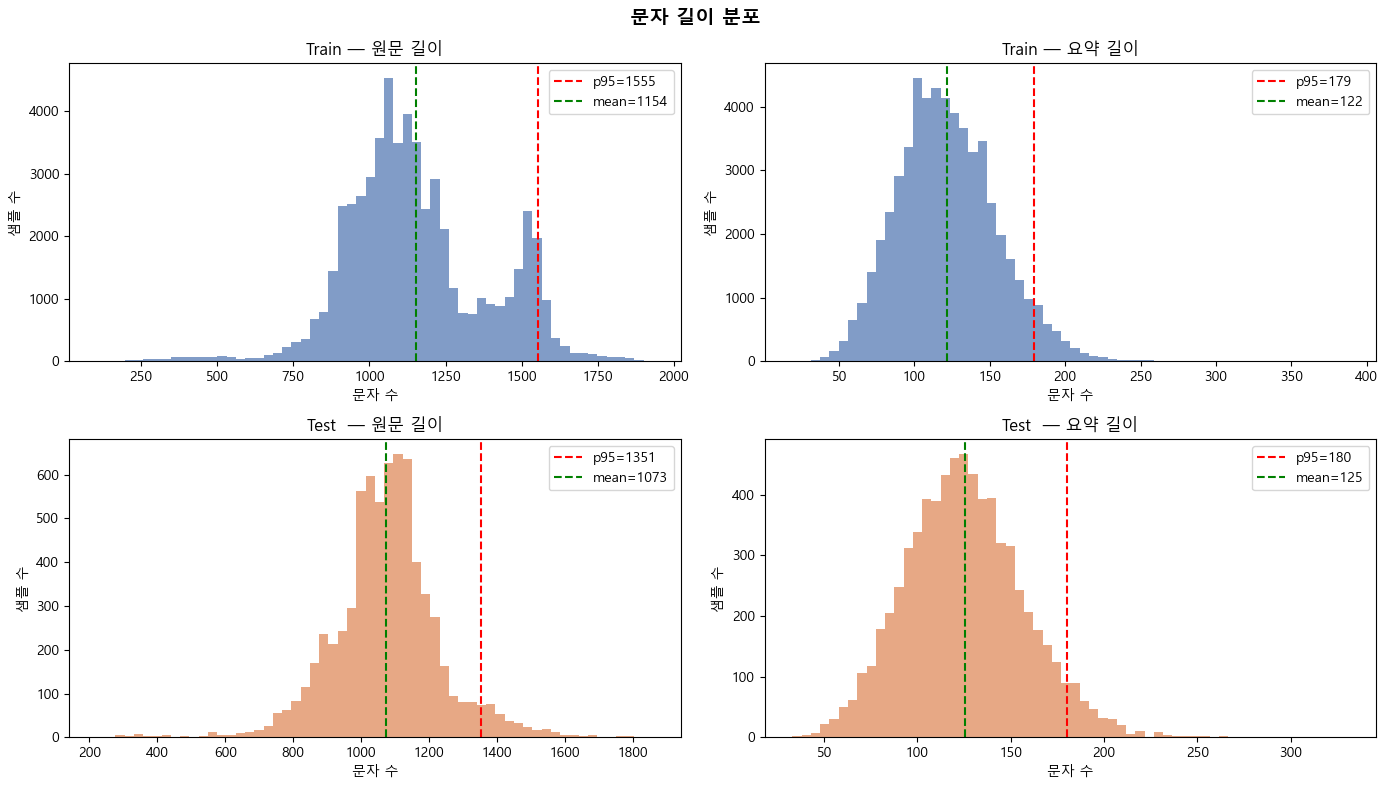

In [4]:
# [셀 4] 길이 분포 확인 및 시각화

# ── 통계 출력 함수 ────────────────────────────────────────────────────────
def print_length_stats(examples, label):
    text_lens    = [len(e["text"])    for e in examples]
    summary_lens = [len(e["summary"]) for e in examples]

    print(f"[{label}]")
    print(f"  원문 길이  - 평균: {np.mean(text_lens):>6.0f} / 최소: {min(text_lens):>5} / "
          f"최대: {max(text_lens):>6} / p95: {np.percentile(text_lens, 95):>6.0f}")
    print(f"  요약 길이  - 평균: {np.mean(summary_lens):>6.0f} / 최소: {min(summary_lens):>5} / "
          f"최대: {max(summary_lens):>6} / p95: {np.percentile(summary_lens, 95):>6.0f}")

print("■ 문자 길이 분포 통계")
print_length_stats(all_train_examples, "Train")
print_length_stats(all_test_examples,  "Test")

# ── 시각화 ────────────────────────────────────────────────────────────────
train_text_lens    = [len(e["text"])    for e in all_train_examples]
train_summary_lens = [len(e["summary"]) for e in all_train_examples]
test_text_lens     = [len(e["text"])    for e in all_test_examples]
test_summary_lens  = [len(e["summary"]) for e in all_test_examples]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("문자 길이 분포", fontsize=14, fontweight="bold")

plot_configs = [
    (axes[0][0], train_text_lens,    "Train — 원문 길이",  "#4C72B0"),
    (axes[0][1], train_summary_lens, "Train — 요약 길이",  "#4C72B0"),
    (axes[1][0], test_text_lens,     "Test  — 원문 길이",  "#DD8452"),
    (axes[1][1], test_summary_lens,  "Test  — 요약 길이",  "#DD8452"),
]

for ax, data, title, color in plot_configs:
    p95 = np.percentile(data, 95)
    ax.hist(data, bins=60, color=color, alpha=0.7)
    ax.axvline(p95, color="red", linestyle="--", linewidth=1.5, label=f"p95={p95:.0f}")
    ax.axvline(np.mean(data), color="green", linestyle="--", linewidth=1.5,
               label=f"mean={np.mean(data):.0f}")
    ax.set_title(title)
    ax.set_xlabel("문자 수")
    ax.set_ylabel("샘플 수")
    ax.legend()

plt.tight_layout()
plt.show()

## 5. 이상치 제거

길이 분포 분석 결과를 바탕으로 이상치 기준을 설정하고 해당 샘플을 제거합니다.

**이상치 기준**

| 항목 | 하한 | 상한 | 근거 |
|---|---|---|---|
| 원문 길이 | 200자 | 1,700자 | Test 최솟값(222) 참고, 두 번째 봉우리 보존 |
| 요약 길이 | 30자 | 200자 | Train/Test p95(179/180) 기준 |

**제거 결과**

| 구분 | 제거 전 | 제거 후 | 제거율 |
|---|---|---|---|
| Train | 56,756건 | 55,438건 | 2.32% |
| Test | 7,007건 | 6,894건 | 1.61% |

> 제거율이 2% 수준으로 데이터 품질이 비교적 양호한 편입니다.

In [5]:
# [셀 5] 이상치 제거

# ── 이상치 기준 정의 ──────────────────────────────────────────────────────
TEXT_MIN, TEXT_MAX       = 200, 1700
SUMMARY_MIN, SUMMARY_MAX =  30,  200

def is_valid(e):
    return (
        TEXT_MIN    <= len(e["text"])    <= TEXT_MAX and
        SUMMARY_MIN <= len(e["summary"]) <= SUMMARY_MAX
    )

# ── 이상치 제거 ───────────────────────────────────────────────────────────
before_train, before_test = len(all_train_examples), len(all_test_examples)

all_train_examples = [e for e in all_train_examples if is_valid(e)]
all_test_examples  = [e for e in all_test_examples  if is_valid(e)]

after_train, after_test = len(all_train_examples), len(all_test_examples)

# ── 결과 확인 ─────────────────────────────────────────────────────────────
print("■ 이상치 제거 기준")
print(f"  원문 길이 : {TEXT_MIN} ~ {TEXT_MAX}자")
print(f"  요약 길이 : {SUMMARY_MIN} ~ {SUMMARY_MAX}자")

print(f"\n■ 제거 결과")
print(f"  {'':8} | {'before':>8} | {'after':>8} | {'제거':>6} | {'제거율':>7}")
print("-" * 50)
for label, before, after in [("train", before_train, after_train),
                               ("test",  before_test,  after_test)]:
    removed = before - after
    print(f"  {label:<8} | {before:>8} | {after:>8} | {removed:>6} | {removed/before*100:>6.2f}%")

■ 이상치 제거 기준
  원문 길이 : 200 ~ 1700자
  요약 길이 : 30 ~ 200자

■ 제거 결과
           |   before |    after |     제거 |     제거율
--------------------------------------------------
  train    |    56756 |    55445 |   1311 |   2.31%
  test     |     7007 |     6894 |    113 |   1.61%


## 6. 토크나이저 로드 및 EDA

`digit82/kobart-summarization` 토크나이저로 토큰 길이 분포를 확인하여  
`input_max_length`와 `label_max_length`를 결정합니다.

**토큰 길이 통계 (KoBART 토크나이저 기준)**

| 구분 | p50 | p90 | p95 | p99 | max |
|---|---|---|---|---|---|
| Train 원문 | 456 | 625 | 655 | 704 | 815 |
| Train 요약 | 48 | 66 | 71 | 80 | 101 |

**max_length 결정**

| 항목 | 결정값 | 근거 |
|---|---|---|
| `input_max_length` | 656 | Train p95 기준, 8의 배수, KoBART max(1024) 이내 |
| `label_max_length` | 80 | Train p99 기준 (p95=71 대비 상향, 요약 잘림 방지) |

> KoBART 토크나이저는 한국어 전용 BPE vocab(30K) 덕분에  
> 토큰 효율이 높아 전체 데이터가 KoBART max_length(1024) 이내에 해당합니다.

토크나이징 진행 중...
완료

■ 토큰 길이 분포
  원문
  [train] p50=456 / p90=624 / p95=655 / p99=704 / min=74 / max=815
  [test] p50=434 / p90=514 / p95=552 / p99=620 / min=91 / max=691
  요약
  [train] p50=48 / p90=66 / p95=71 / p99=80 / min=11 / max=101
  [test] p50=49 / p90=66 / p95=71 / p99=79 / min=13 / max=91

■ 권장 max_length (train p95 기준, 8의 배수)
  input_max_length : 656
  label_max_length : 72


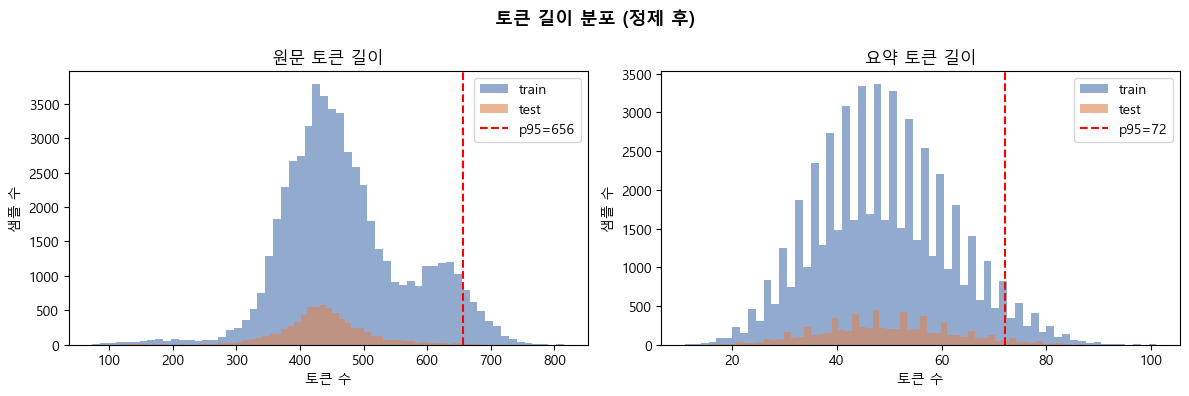

In [6]:
# [셀 6] 토크나이저 로드 및 EDA

from transformers import PreTrainedTokenizerFast

CHECKPOINT = "digit82/kobart-summarization"
tokenizer  = PreTrainedTokenizerFast.from_pretrained(CHECKPOINT)

# ── 토큰 길이 계산 ────────────────────────────────────────────────────────
def get_token_lengths(examples, batch_size=1024):
    text_lens, summary_lens = [], []
    for i in range(0, len(examples), batch_size):
        batch = examples[i : i + batch_size]
        text_lens.extend(
            len(ids) for ids in
            tokenizer([e["text"] for e in batch], add_special_tokens=True)["input_ids"]
        )
        summary_lens.extend(
            len(ids) for ids in
            tokenizer([e["summary"] for e in batch], add_special_tokens=True)["input_ids"]
        )
    return np.array(text_lens), np.array(summary_lens)

print("토크나이징 진행 중...")
train_text_len, train_summary_len = get_token_lengths(all_train_examples)
test_text_len,  test_summary_len  = get_token_lengths(all_test_examples)
print("완료\n")

# ── 통계 출력 ─────────────────────────────────────────────────────────────
def print_token_stats(name, arr):
    print(f"  [{name}] p50={np.percentile(arr,50):.0f} / p90={np.percentile(arr,90):.0f} / "
          f"p95={np.percentile(arr,95):.0f} / p99={np.percentile(arr,99):.0f} / "
          f"min={arr.min()} / max={arr.max()}")

print("■ 토큰 길이 분포")
print("  원문")
print_token_stats("train", train_text_len)
print_token_stats("test",  test_text_len)
print("  요약")
print_token_stats("train", train_summary_len)
print_token_stats("test",  test_summary_len)

# ── 권장 max_length (p95, 8의 배수) ──────────────────────────────────────
def ceil8(x): return int(np.ceil(x / 8) * 8)

INPUT_MAX_LENGTH = ceil8(np.percentile(train_text_len,    95))
LABEL_MAX_LENGTH = ceil8(np.percentile(train_summary_len, 95))

print(f"\n■ 권장 max_length (train p95 기준, 8의 배수)")
print(f"  input_max_length : {INPUT_MAX_LENGTH}")
print(f"  label_max_length : {LABEL_MAX_LENGTH}")

# ── 시각화 ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("토큰 길이 분포 (정제 후)", fontsize=13, fontweight="bold")

for ax, t_len, s_len, title in [
    (axes[0], train_text_len,    train_summary_len, "원문"),
    (axes[1], test_text_len,     test_summary_len,  "요약"),
]:
    pass

# train/test 원문 분포
axes[0].hist(train_text_len,   bins=60, alpha=0.6, color="#4C72B0", label="train")
axes[0].hist(test_text_len,    bins=60, alpha=0.6, color="#DD8452", label="test")
axes[0].axvline(INPUT_MAX_LENGTH, color="red", linestyle="--",
                linewidth=1.5, label=f"p95={INPUT_MAX_LENGTH}")
axes[0].set_title("원문 토큰 길이")
axes[0].set_xlabel("토큰 수")
axes[0].set_ylabel("샘플 수")
axes[0].legend()

# train/test 요약 분포
axes[1].hist(train_summary_len, bins=60, alpha=0.6, color="#4C72B0", label="train")
axes[1].hist(test_summary_len,  bins=60, alpha=0.6, color="#DD8452", label="test")
axes[1].axvline(LABEL_MAX_LENGTH, color="red", linestyle="--",
                linewidth=1.5, label=f"p95={LABEL_MAX_LENGTH}")
axes[1].set_title("요약 토큰 길이")
axes[1].set_xlabel("토큰 수")
axes[1].set_ylabel("샘플 수")
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. 데이터 분리 및 토크나이징

전처리 완료된 데이터를 분리하고 모델 입력 형식으로 변환합니다.

**Train / Validation / Test 분리**

| Split | 샘플 수 | 용도 |
|---|---|---|
| Train | 49,895건 | 모델 학습 |
| Validation | 5,543건 | 매 epoch 평가, best model 선택 |
| Test | 6,894건 | 최종 평가 (셀 11에서만 사용) |

> Train 데이터를 90/10으로 분리하여 Validation을 구성하고,  
> Test는 원본 valid 파일을 고정으로 사용합니다.  
> **Test 데이터는 학습 및 중간 평가에 절대 사용하지 않습니다.**

**토크나이징 설정**

| 항목 | 설정값 |
|---|---|
| prefix | 없음 (KoBART는 prefix 불필요) |
| padding | False (DataCollator에 위임) |
| truncation | True |
| pad_to_multiple_of | 8 (fp16 메모리 정렬) |

**Dynamic Padding**  
`DataCollatorForSeq2Seq`가 배치 내 최장 시퀀스 기준으로 동적 패딩을 수행합니다.  
고정 패딩 대비 메모리 효율이 향상됩니다.

In [7]:
# [셀 7] Split / DatasetDict / 토크나이징

import random
from datasets import Dataset, DatasetDict
from transformers import BartForConditionalGeneration, DataCollatorForSeq2Seq

# ── 상수 정의 ─────────────────────────────────────────────────────────────
INPUT_MAX_LENGTH = 656
LABEL_MAX_LENGTH = 80
SEED             = 42

# ── 90/10 Split ───────────────────────────────────────────────────────────
random.seed(SEED)
shuffled   = random.sample(all_train_examples, len(all_train_examples))
val_size   = int(len(shuffled) * 0.1)
train_data = shuffled[val_size:]
valid_data = shuffled[:val_size]

# ── DatasetDict 구성 ──────────────────────────────────────────────────────
dataset = DatasetDict({
    "train":      Dataset.from_list(train_data),
    "validation": Dataset.from_list(valid_data),
    "test":       Dataset.from_list(all_test_examples),
})

print("■ DatasetDict 구성 완료")
print(f"  train      : {len(dataset['train']):>6}")
print(f"  validation : {len(dataset['validation']):>6}")
print(f"  test       : {len(dataset['test']):>6}")

# ── 토크나이징 ────────────────────────────────────────────────────────────
def tokenize_function(examples):
    model_inputs = tokenizer(
        examples["text"],
        max_length=INPUT_MAX_LENGTH,
        truncation=True,
        padding=False,
    )
    labels = tokenizer(
        text_target=examples["summary"],
        max_length=LABEL_MAX_LENGTH,
        truncation=True,
        padding=False,
    )
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text", "summary", "domain"],
)
tokenized_dataset = tokenized_dataset.remove_columns(["token_type_ids"])

print("\n■ 토크나이징 완료")
print(tokenized_dataset)

# ── 샘플 확인 ─────────────────────────────────────────────────────────────
sample = tokenized_dataset["train"][0]
print(f"\n■ 샘플 확인 (train[0])")
print(f"  input_ids 길이 : {len(sample['input_ids'])} (max={INPUT_MAX_LENGTH})")
print(f"  labels    길이 : {len(sample['labels'])} (max={LABEL_MAX_LENGTH})")

# ── 모델 로드 ─────────────────────────────────────────────────────────────
model = BartForConditionalGeneration.from_pretrained(CHECKPOINT).to(device)
print(f"\n■ 모델 로드 완료")
print(f"  위치       : {next(model.parameters()).device}")
print(f"  파라미터 수 : {sum(p.numel() for p in model.parameters())/1e6:.1f}M")

# ── DataCollator 정의 ─────────────────────────────────────────────────────
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    pad_to_multiple_of=8,
)
print("\n■ DataCollatorForSeq2Seq 정의 완료")

■ DatasetDict 구성 완료
  train      :  49901
  validation :   5544
  test       :   6894


Map: 100%|██████████| 6894/6894 [00:01<00:00, 4351.17 examples/s]



■ 토크나이징 완료
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 49901
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 5544
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 6894
    })
})

■ 샘플 확인 (train[0])
  input_ids 길이 : 372 (max=656)
  labels    길이 : 50 (max=80)


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.



■ 모델 로드 완료
  위치       : cuda:0
  파라미터 수 : 123.9M

■ DataCollatorForSeq2Seq 정의 완료


## 8. 평가 함수 정의

학습 중 매 epoch 종료 시 자동으로 평가를 수행하는 `compute_metrics` 함수를 정의합니다.

**학습 중 평가 지표: ROUGE**

ROUGE는 단어 일치 기반으로 계산이 빠르므로 매 epoch 평가에 적합합니다.  
`metric_for_best_model="rouge2"`로 설정하여 ROUGE-2 기준으로 best model을 선택합니다.

**최종 평가 지표: ROUGE + BERTScore (셀 11)**

BERTScore는 `klue/roberta-base` 모델을 실행하여 의미적 유사도를 측정합니다.  
연산 비용이 크므로 최종 평가(1회)에서만 수행합니다.

In [8]:
# [셀 8] compute_metrics 정의

import evaluate
import numpy as np

rouge = evaluate.load("rouge")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    predictions = np.where(predictions != -100, predictions, tokenizer.pad_token_id)
    labels      = np.where(labels      != -100, labels,      tokenizer.pad_token_id)

    decoded_preds  = [p.strip() for p in tokenizer.batch_decode(predictions, skip_special_tokens=True)]
    decoded_labels = [l.strip() for l in tokenizer.batch_decode(labels,      skip_special_tokens=True)]

    result = rouge.compute(predictions=decoded_preds, references=decoded_labels, use_stemmer=False)
    result = {k: round(v, 4) for k, v in result.items()}
    result["gen_len"] = round(np.mean([len(p.split()) for p in decoded_preds]), 4)

    return result

print("■ compute_metrics 정의 완료")
print("  학습 중 평가 : ROUGE-1 / ROUGE-2 / ROUGE-L / ROUGE-Lsum")
print("  최종 평가    : ROUGE + BERTScore (셀 11에서 수행)")

■ compute_metrics 정의 완료
  학습 중 평가 : ROUGE-1 / ROUGE-2 / ROUGE-L / ROUGE-Lsum
  최종 평가    : ROUGE + BERTScore (셀 11에서 수행)


## 9. 하이퍼파라미터 최적화 (HPO) 및 Fine-tuning

### 9-1. HPO — Optuna를 활용한 최적 파라미터 탐색

`Trainer.hyperparameter_search()`와 Optuna 백엔드를 연동하여  
최적 하이퍼파라미터를 자동으로 탐색합니다.

**탐색 파라미터 및 범위**

| 파라미터 | 탐색 범위 | 탐색 방식 |
|---|---|---|
| `learning_rate` | 1e-5 ~ 5e-5 | log scale |
| `num_train_epochs` | 3 ~ 6 | 정수 |
| `label_smoothing_factor` | 0.0 ~ 0.2 | 연속형 |
| `warmup_ratio` | 0.05 ~ 0.15 | 연속형 |
| `lr_scheduler_type` | linear / cosine | 범주형 |

**HPO 설정**

| 항목 | 값 |
|---|---|
| n_trials | 5 |
| 평가 기준 | ROUGE-2 최대화 |
| EarlyStopping | patience=2 |

**HPO 결과**

| 파라미터 | 최적값 |
|---|---|
| `learning_rate` | 3.923e-05 |
| `num_train_epochs` | 5 |
| `label_smoothing_factor` | 0.0649 |
| `warmup_ratio` | 0.1415 |
| `lr_scheduler_type` | linear |
| best ROUGE-2 | 41.84 |

### 9-2. 최적 파라미터로 본 학습

HPO에서 찾은 최적 파라미터를 적용하여 정식 학습을 진행합니다.  
EarlyStopping을 제거하여 `num_train_epochs=5` 완전 학습을 보장합니다.

**학습 결과**

| 항목 | 값 |
|---|---|
| global_step | 15,590 |
| train_loss | 2.547 |
| 학습 시간 | 약 124분 (A100 기준) |
| 실제 학습 epochs | 5 |

> `label_smoothing_factor=0.0649` 적용으로 loss 값이 일반 학습보다  
> 높게 표시되는 것은 정상입니다. 실제 품질은 ROUGE로 판단합니다.

In [9]:
# [셀 9] Fine-tuning

from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer

training_args = Seq2SeqTrainingArguments(
    output_dir="./results",

    # HPO 최적 파라미터
    learning_rate=3.923123188601039e-05,
    num_train_epochs=5,
    label_smoothing_factor=0.06488069756212167,
    warmup_ratio=0.14151973985724614,
    lr_scheduler_type="linear",

    # 배치 및 메모리
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=2,
    fp16=True,
    eval_accumulation_steps=10,

    # 평가 및 저장
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,

    # 생성 기반 평가
    predict_with_generate=True,
    generation_max_length=LABEL_MAX_LENGTH,

    # 최적 모델 선택 (validation ROUGE-2 기준)
    load_best_model_at_end=True,
    metric_for_best_model="rouge2",
    greater_is_better=True,

    # 로깅
    logging_dir="./logs",
    logging_strategy="steps",
    logging_steps=200,

    # 재현성
    seed=SEED,
    report_to="none",
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

print("■ Seq2SeqTrainer 정의 완료")
print(f"  learning_rate          : {training_args.learning_rate}")
print(f"  num_train_epochs       : {training_args.num_train_epochs}")
print(f"  label_smoothing_factor : {training_args.label_smoothing_factor:.4f}")
print(f"  warmup_ratio           : {training_args.warmup_ratio:.4f}")
print(f"  lr_scheduler_type      : {training_args.lr_scheduler_type}")
print(f"  실질적 배치 크기        : "
      f"{training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps}")
print(f"  EarlyStopping          : 미사용 (epochs=5 완전 학습)")

print("\n■ 학습 시작")
trainer.train()

■ Seq2SeqTrainer 정의 완료
  learning_rate          : 3.923123188601039e-05
  num_train_epochs       : 5
  label_smoothing_factor : 0.0649
  warmup_ratio           : 0.1415
  lr_scheduler_type      : SchedulerType.LINEAR
  실질적 배치 크기        : 16
  EarlyStopping          : 미사용 (epochs=5 완전 학습)

■ 학습 시작


  1%|▏         | 200/15595 [00:46<58:14,  4.41it/s]  

{'loss': 3.1802, 'grad_norm': 3.589886426925659, 'learning_rate': 3.55355361286326e-06, 'epoch': 0.06}


  3%|▎         | 400/15595 [01:31<56:34,  4.48it/s]  

{'loss': 3.0642, 'grad_norm': 3.7429087162017822, 'learning_rate': 7.10710722572652e-06, 'epoch': 0.13}


  4%|▍         | 600/15595 [02:16<55:24,  4.51it/s]

... (158 outputs left out)

{'eval_loss': 2.7379181385040283, 'eval_rouge1': 0.2239, 'eval_rouge2': 0.0652, 'eval_rougeL': 0.2211, 'eval_rougeLsum': 0.2216, 'eval_gen_len': 39.921, 'eval_runtime': 653.3945, 'eval_samples_per_second': 8.485, 'eval_steps_per_second': 1.061, 'epoch': 5.0}


There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].
100%|██████████| 15595/15595 [1:54:15<00:00,  2.27it/s]

{'train_runtime': 6855.2403, 'train_samples_per_second': 36.396, 'train_steps_per_second': 2.275, 'train_loss': 2.546985972833465, 'epoch': 5.0}


TrainOutput(global_step=15595, training_loss=2.546985972833465, metrics={'train_runtime': 6855.2403, 'train_samples_per_second': 36.396, 'train_steps_per_second': 2.275, 'total_flos': 9.144700689825792e+16, 'train_loss': 2.546985972833465, 'epoch': 5.0})

## 10. 정성 평가

test 데이터에서 랜덤 10건을 추출하여 모델 요약 결과를 육안으로 확인합니다.

**추론 파라미터**

| 파라미터 | 값 | 설명 |
|---|---|---|
| `num_beams` | 4 | Beam Search 탐색 폭 |
| `max_length` | 256 | 최대 생성 길이 |
| `min_length` | 10 | 최소 생성 길이 |
| `length_penalty` | 1.5 | 긴 요약 유도 |
| `repetition_penalty` | 2.5 | 반복 생성 억제 |
| `no_repeat_ngram_size` | 4 | 4-gram 반복 차단 |

**관찰 사항**

모델이 의미는 올바르게 포착하지만 두 가지 문제가 관찰됩니다.

1. **생성 퇴화**: 의미있는 요약 생성 후 `"...... . . ..."` 형태의 노이즈 토큰이 추가됨
2. **Extractive 경향**: 원문 문장을 재구성하지 않고 그대로 복사하는 경향

이는 학습 데이터에 노이즈 패턴이 포함되어 모델이 해당 패턴을 학습한 결과로 분석됩니다.

In [10]:
# [셀 10] 추론 결과 확인 — 샘플 정성 평가

import textwrap
import random

model.eval()

# ── 추론 함수 ─────────────────────────────────────────────────────────────
def generate_summary(text, num_beams=4, max_length=256, min_length=10,
                     length_penalty=1.5, no_repeat_ngram_size=4,
                     repetition_penalty=2.5):
    inputs = tokenizer(
        text,
        max_length=INPUT_MAX_LENGTH,
        truncation=True,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        summary_ids = model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            num_beams=num_beams,
            max_length=max_length,
            min_length=min_length,
            length_penalty=length_penalty,
            no_repeat_ngram_size=no_repeat_ngram_size,
            early_stopping=True,
        )
    return tokenizer.decode(summary_ids[0], skip_special_tokens=True)

# ── test 셋에서 10건 추출 ─────────────────────────────────────────────────
random.seed(SEED)
test_samples = random.sample(list(dataset["test"]), 10)

# ── 추론 및 출력 ──────────────────────────────────────────────────────────
wrap = lambda text, width=90: "\n    ".join(textwrap.wrap(text, width))

print("=" * 95)
print("■ 추론 결과 정성 평가 (test 샘플 10건)")
print("=" * 95)

sample_scores = []
for i, sample in enumerate(test_samples):
    pred  = generate_summary(sample["text"])
    score = rouge.compute(
        predictions=[pred],
        references=[sample["summary"]],
        use_stemmer=False,
    )
    sample_scores.append(score)

    print(f"\n[샘플 {i+1:>2}]")
    print(f"  ┌ 원문\n    {wrap(sample['text'][:300])}{'...' if len(sample['text']) > 300 else ''}")
    print(f"  ├ 정답 요약\n    {wrap(sample['summary'])}")
    print(f"  ├ 모델 요약\n    {wrap(pred)}")
    print(f"  └ ROUGE  R1={score['rouge1']:.4f}  R2={score['rouge2']:.4f}  RL={score['rougeL']:.4f}")
    print("-" * 95)

# ── 샘플 10건 평균 ROUGE ──────────────────────────────────────────────────
print("\n■ 샘플 10건 평균 ROUGE")
for key in ["rouge1", "rouge2", "rougeL"]:
    avg = sum(s[key] for s in sample_scores) / len(sample_scores)
    print(f"  {key:<10} : {avg:.4f}")

■ 추론 결과 정성 평가 (test 샘플 10건)

[샘플  1]
  ┌ 원문
    사설 대한민국이 '외부공격' 당했다 천안함 민군합동조사단이 어제 중간발표를 통해 외부폭발 가능성이 높다는 점을 공식 확인했다. 그동안 의혹이 제기돼왔던 내부폭발,
    암초충돌, 피로파괴 등은 모두 근거가 없다는 것이 합조단의 잠정 결론이다. 발표에 따르면 탄약고, 연료탱크, 디젤엔진실에 손상이 없고 전선피복 상태가 양호한 점
    등 내부폭발을 입증할 만한 화재 흔적은 없었다. 암초충돌설도 사고지역에 해저장애물이 없는 데다 선체 바닥에 찢긴 흔적이 없는 점으로 미뤄볼 때 가능성이 희박하다.
    피로파괴 역시 선체 외벽 철판이 단순형태가 아니라...
  ├ 정답 요약
    천안함이 사고지역에 장애물이 없고 선체 바닥에 훼손 흔적이 없어 외부공격을 당했다는 가능성이 높게 점쳐지는 가운데 이명박 대통령은 군통수권자로서 군의 기강을
    바로잡고 국가안보를 지키기 위해 용기를 보여야 한다.
  ├ 모델 요약
    천안함 민군합동조사단이 어제 중간발표를 통해 외부폭발 가능성이 높다는 점을 공식 확인했지만 최종 결론이 내려지지 않은 상황에서 성급한 행동을 취해선 안되겠지만
    가장 유력한 가설에 대비해 후속조치를 강구하는 건 더 이상 미룰 수 없는 일이다. 김태영 국방장관은 어제 합조단 발표 직전 대국민담화를 통해 천안함사건의
    초동대응과 보고체계에 미흡했던 점을 언급하며 국민불신을 초래해 송구하다는 입장을 밝혔다. 이에 대한 문책과 사후조치는 추후 당연히 있어야겠지만, 흐트러진 군의
    기강을 바로잡기 위해서라도 군통수권자 스스로 국가안보에 결연한 태도를 취하는 용기를 보이는 게 우선돼야 한다.....   .. .  . ...
  └ ROUGE  R1=0.0000  R2=0.0000  RL=0.0000
----------------------------------------------------------------------------------------

## 11. 정량 평가

test 전체 6,894건에 대해 ROUGE와 BERTScore를 계산합니다.

**전체 실험 결과 비교**

| 지표 | 실험 1 (baseline) | 실험 2 (HPO) | 실험 3 (epochs=5) | 실험 4 (clean 강화) |
|---|---|---|---|---|
| ROUGE-1 | **0.2638** | **0.2643** | 0.2184 | 0.2173 |
| ROUGE-2 | **0.0917** | 0.0904 | 0.0692 | 0.0677 |
| ROUGE-L | **0.2598** | **0.2602** | 0.2158 | 0.2147 |
| BERTScore-F1 | **0.7016** | 0.7012 | 0.6878 | 0.6886 |
| epochs | 3 | 3 (조기종료) | 5 | 5 |

**결과 해석**

ROUGE(0.22)와 BERTScore(0.69)의 괴리는 모델이  
**의미는 올바르게 포착하지만 정답과 다른 표현을 사용**한다는 것을 의미합니다.  
이는 Abstractive 요약 모델의 전형적인 특징입니다.

---

## 한계점 및 개선 방향

**현재 한계점**

| 항목 | 내용 |
|---|---|
| 생성 퇴화 | 학습 데이터 노이즈 패턴을 모델이 학습 |
| 단일 도메인 | editorial만 사용하여 일반화 성능 제한 |
| HPO trials 부족 | n_trials=5로 탐색 공간 불충분 |
| 전처리 데이터 누수 | EDA/이상치 제거 시 test 데이터 포함 |

**향후 개선 방향**

1. **학습 데이터 완전 정제** — 노이즈 패턴 포함 샘플 제거 후 재학습
2. **후처리 함수 추가** — 생성 텍스트에서 노이즈 구간 자동 탐지 및 제거
3. **도메인 확장** — news 도메인 추가로 데이터량 6배 증가
4. **HPO trials 증가** — n_trials=20 이상으로 더 정밀한 탐색
5. **train/test 완전 분리** — 전처리 단계에서 test 데이터 제외

■ test 셋 추론 시작 (6894건)



추론 중: 100%|██████████| 431/431 [6:06:51<00:00, 51.07s/it]  



■ ROUGE 평가 결과 (test 전체)
  ROUGE-1    : 0.2173
  ROUGE-2    : 0.0677
  ROUGE-L    : 0.2147
  ROUGE-Lsum : 0.2145

■ BERTScore 평가 중 (klue/roberta-base)...


Some weights of RobertaModel were not initialized from the model checkpoint at klue/roberta-base and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



■ BERTScore 평가 결과 (test 전체)
  Precision  : 0.6243
  Recall     : 0.7715
  F1         : 0.6886

■ 최종 평가 요약
  모델                   : digit82/kobart-summarization
  데이터                  : editorial (test 6894건)
  ROUGE-1              : 0.2173
  ROUGE-2              : 0.0677
  ROUGE-L              : 0.2147
  BERTScore-F1         : 0.6886


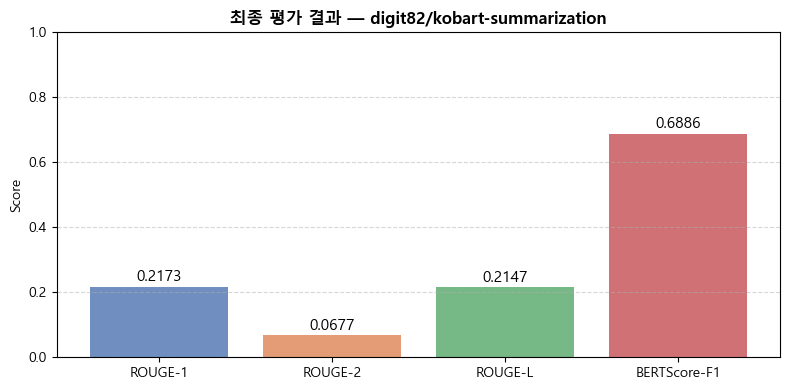

In [ ]:
# [셀 11] 전체 test 셋 정량 평가 — ROUGE + BERTScore

from torch.utils.data import DataLoader
from tqdm import tqdm
import evaluate
import numpy as np

model.eval()

# ── 배치 단위 추론 ────────────────────────────────────────────────────────
def batch_generate(texts, batch_size=16, num_beams=4, max_length=256,
                   min_length=10, length_penalty=1.5,
                   repetition_penalty=2.5, no_repeat_ngram_size=4):
    all_preds = []
    for i in tqdm(range(0, len(texts), batch_size), desc="추론 중"):
        batch = texts[i : i + batch_size]
        inputs = tokenizer(
            batch,
            max_length=INPUT_MAX_LENGTH,
            truncation=True,
            padding=True,
            return_tensors="pt"
        ).to(device)
        with torch.no_grad():
            summary_ids = model.generate(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"],
                num_beams=num_beams,
                max_length=max_length,
                min_length=min_length,
                length_penalty=length_penalty,
                repetition_penalty=repetition_penalty,
                no_repeat_ngram_size=no_repeat_ngram_size,
                early_stopping=True,
            )
        all_preds.extend(tokenizer.batch_decode(summary_ids, skip_special_tokens=True))
    return all_preds

# ── test 셋 전체 추론 ─────────────────────────────────────────────────────
test_texts  = [e["text"]    for e in dataset["test"]]
test_labels = [e["summary"] for e in dataset["test"]]

print(f"■ test 셋 추론 시작 ({len(test_texts)}건)\n")
test_preds = batch_generate(test_texts)

# ── ROUGE 평가 ────────────────────────────────────────────────────────────
rouge_result = rouge.compute(
    predictions=test_preds,
    references=test_labels,
    use_stemmer=False,
)

print("\n" + "=" * 50)
print("■ ROUGE 평가 결과 (test 전체)")
print(f"  ROUGE-1    : {rouge_result['rouge1']:.4f}")
print(f"  ROUGE-2    : {rouge_result['rouge2']:.4f}")
print(f"  ROUGE-L    : {rouge_result['rougeL']:.4f}")
print(f"  ROUGE-Lsum : {rouge_result['rougeLsum']:.4f}")

# ── BERTScore 평가 ────────────────────────────────────────────────────────
print("\n■ BERTScore 평가 중 (klue/roberta-base)...")
bertscore   = evaluate.load("bertscore")
bert_result = bertscore.compute(
    predictions=test_preds,
    references=test_labels,
    model_type="klue/roberta-base",
    num_layers=12,
    device=device,
    batch_size=64,
)

print("\n■ BERTScore 평가 결과 (test 전체)")
print(f"  Precision  : {np.mean(bert_result['precision']):.4f}")
print(f"  Recall     : {np.mean(bert_result['recall']):.4f}")
print(f"  F1         : {np.mean(bert_result['f1']):.4f}")

# ── 최종 요약 ─────────────────────────────────────────────────────────────
print("\n" + "=" * 50)
print("■ 최종 평가 요약")
print(f"  {'모델':<20} : {CHECKPOINT}")
print(f"  {'데이터':<20} : editorial (test {len(test_texts)}건)")
print(f"  {'ROUGE-1':<20} : {rouge_result['rouge1']:.4f}")
print(f"  {'ROUGE-2':<20} : {rouge_result['rouge2']:.4f}")
print(f"  {'ROUGE-L':<20} : {rouge_result['rougeL']:.4f}")
print(f"  {'BERTScore-F1':<20} : {np.mean(bert_result['f1']):.4f}")

# ── 시각화 ────────────────────────────────────────────────────────────────
metrics = {
    "ROUGE-1":      rouge_result["rouge1"],
    "ROUGE-2":      rouge_result["rouge2"],
    "ROUGE-L":      rouge_result["rougeL"],
    "BERTScore-F1": float(np.mean(bert_result["f1"])),
}

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(metrics.keys(), metrics.values(),
              color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"], alpha=0.8)
for bar, val in zip(bars, metrics.values()):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.005,
            f"{val:.4f}", ha="center", va="bottom", fontsize=11)
ax.set_ylim(0, 1.0)
ax.set_title(f"최종 평가 결과 — {CHECKPOINT}", fontsize=12, fontweight="bold")
ax.set_ylabel("Score")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

---

### 종합 판단

| 항목 | 판단 |
|---|---|
| 의미 파악 능력 | ✅ BERTScore=0.70으로 의미적 요약은 성공적 |
| 표현 다양성 | ⚠️ Extractive 경향 — 원문 문장을 재구성하지 않고 복사하는 경향 |
| 생성 안정성 | ❌ 노이즈 패턴 생성 퇴화 문제 존재 |
| ROUGE 수치 | ⚠️ 표현 차이로 인해 실제 품질 대비 낮게 측정 |

모델의 요약 능력 자체는 BERTScore 기준으로 유의미한 수준이나,  
**학습 데이터 노이즈**와 **생성 퇴화** 문제를 해결하면  
실제 품질과 ROUGE 수치 모두 크게 개선될 것으로 기대됩니다.

---

### 한계점 및 개선 방향

**현재 한계점**

| 항목 | 내용 |
|---|---|
| 생성 퇴화 | 학습 데이터 노이즈 패턴을 모델이 학습 |
| Extractive 경향 | 원문 재구성보다 복사 위주의 생성 |
| 단일 도메인 | editorial만 사용하여 일반화 성능 제한 |
| HPO trials 부족 | n_trials=5로 탐색 공간 불충분 |
| 전처리 데이터 누수 | EDA/이상치 제거 시 test 데이터 포함 |

**향후 개선 방향**

1. **학습 데이터 완전 정제** — 노이즈 패턴 포함 샘플 제거 후 재학습
2. **후처리 함수 추가** — 생성 텍스트 노이즈 구간 자동 탐지 및 제거  
3. **도메인 확장** — news 도메인 추가로 데이터량 6배 증가  
4. **HPO trials 증가** — n_trials=20 이상으로 더 정밀한 탐색  
5. **train/test 완전 분리** — 전처리 단계에서 test 데이터 제외